<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Weather Service](https://github.com/Query-farm/vgi-nws)

Explore US weather alerts, observations, forecast grids, bulletins, and river conditions.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nws/blob/main/notebooks/04_nearby_gauges_are_not_a_river_network.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nws/blob/main/notebooks/README.md)


## 04 · Nearby gauges are not a river network

Which gauges are geographically close, and which are connected upstream or downstream?
These are different joins. We first compare both sets, then read the selected gauge's
stage, thresholds and historical context without mixing flow units or vertical datums.
All conditions and identifiers' associations below are synthetic teaching inputs.

### Change the geographic search radius

Use **RADIUS_KM = 25**, then try **50**. The point and selected gauge RMDV2 remain
fixed. Only the geographic candidate set changes; river connectivity and the selected
gauge's time series must remain identical. A nearby gauge is not automatically an
upstream warning station or a substitute for local measurements.

In [1]:
RADIUS_KM = 25  # Experiment: 50; supported range 10–100 km

### Run independently

Read the saved results on GitHub or choose **Open in Colab** and Run All. The brief
base install preserves compatible preloaded plotting and kernel libraries. Local
publication uses the optional `[runner]` extra. Initial packages, verified companions,
VGI and native worker download need internet. No worker checkout, Bun or source build
is required. Hosted Colab is not tested; a fresh preloaded Python 3.12 notebook-only
execution checks the common setup path. [Detailed setup and provenance](README.md).

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.40":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.40"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.40":
    raise RuntimeError("Install shared tools 0.3.40, restart, and Run All.")

In [3]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("nws")
from scenario_source import ScenarioSource

%matplotlib inline
theme()
session = connect(globals())
con = session.connection
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
assert con.execute("SELECT current_setting('TimeZone')").fetchone()[0] == "UTC"
source = ScenarioSource()
Path("artifacts").mkdir(exist_ok=True)
PROVENANCE = "Source: synthetic NOAA-shaped teaching inputs · 2 January 2026 UTC · not live conditions"

if type(RADIUS_KM) not in (int, float) or not np.isfinite(RADIUS_KM) or not 10 <= RADIUS_KM <= 100:
    raise ValueError("RADIUS_KM must be finite from 10 through 100")

### Source boundary

Every value in this story is **synthetic**. The real released NWS worker parses
NOAA-shaped documents served only on loopback; all ten upstream roots are scoped to
that local service and unknown requests fail. No real alert, gauge condition or forecast
is represented. Canonical `source_url` values are emitted by the worker even in this
mode: they describe product routes, not proof of a live request. `fetched_at` is the
local read time. The fixture's fixed scenario time is **2026-01-02 12:00 UTC**.

Shared setup uses an empty temporary SQL-secret directory, disables persistence and
JupySQL default connection autoload, and fixes the connection timezone to UTC. No key,
saved secret or account write is involved. Cleanup closes the connection/service and
restores the temporary process environment.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nws' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-nws@v0.4.0');

,Success


### Compare geography with reported connectivity

The regional gauge index provides a broad population. `gauges_near` applies a distance
cutoff; `river_network` instead returns the selected gauge's reported upstream and
downstream identifiers. Neither set is inferred from the other.

The `compat` schema accepts positional JSON options for clients that need correlated
calls without named arguments. We use the same options through both interfaces and
compare every returned business field. This is an interface-equivalence check, not a
second independent data source. Fetch times and canonical URLs remain provenance fields.

In [5]:
%%sql
CREATE TABLE region AS SELECT * FROM nws.main.gauges(bbox:='-78,37,-76,39',state:='VA');
CREATE TABLE nearby AS SELECT * FROM nws.main.gauges_near(37.5407,-77.4360,radius_km:={{RADIUS_KM}},state:='VA');
CREATE TABLE nearby_compat AS SELECT * FROM nws.compat.gauges_near(37.5407,-77.4360,json_object('radius_km',{{RADIUS_KM}},'state','VA'));
CREATE TABLE network AS SELECT * FROM nws.main.river_network('RMDV2',direction:='both');
CREATE TABLE network_compat AS SELECT * FROM nws.compat.river_network('RMDV2','{"direction":"both"}');
SELECT gauge_id,name,distance_km,observed_at,observed_category FROM nearby ORDER BY distance_km;
SELECT direction,gauge_id,sequence_number FROM network ORDER BY direction,sequence_number;
SELECT (SELECT count(*) FROM region) AS regional_rows,(SELECT count(*) FROM nearby) AS nearby_rows,
 (SELECT count(*) FROM network) AS connected_rows,
 (SELECT count(*) FROM nearby JOIN network USING(gauge_id)) AS shared_identifiers;

,regional_rows,nearby_rows,connected_rows,shared_identifiers
0,3,1,3,0


In [6]:
%%sql nearby <<
SELECT * FROM nearby ORDER BY distance_km;

In [7]:
%%sql region <<
SELECT gauge_id,latitude,longitude FROM region ORDER BY gauge_id;

In [8]:
%%sql network <<
SELECT * FROM network ORDER BY direction,sequence_number;

In [9]:
prose(
    f"The **{RADIUS_KM:g} km** search returns **{len(nearby)} gauges** from a regional index of **{len(region)}**. The reported network has **{len(network)} other gauges**, with **{len(set(nearby.gauge_id) & set(network.gauge_id))} identifiers in common**. In these inputs, proximity is not connectivity. A returned candidate can also have a NULL observation time and `not_current` status."
)

The **25 km** search returns **1 gauges** from a regional index of **3**. The reported network has **3 other gauges**, with **0 identifiers in common**. In these inputs, proximity is not connectivity. A returned candidate can also have a NULL observation time and `not_current` status.

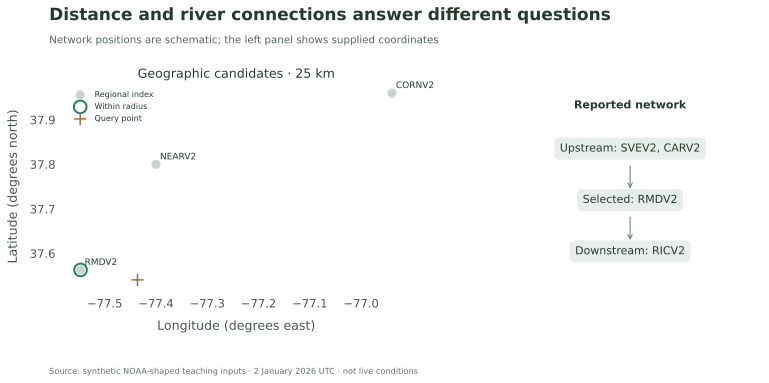

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.scatter(region.longitude, region.latitude, color="#C7D4CE", s=65, label="Regional index")
ax.scatter(
    nearby.longitude,
    nearby.latitude,
    facecolors="none",
    edgecolors="#287D68",
    linewidths=2,
    s=160,
    label="Within radius",
)
ax.scatter([-77.436], [37.5407], marker="+", color="#A46F3E", s=150, label="Query point")
for r in region.itertuples():
    ax.annotate(r.gauge_id, (r.longitude, r.latitude), xytext=(4, 5), textcoords="offset points", fontsize=9)
ax.set(
    xlabel="Longitude (degrees east)",
    ylabel="Latitude (degrees north)",
    title=f"Geographic candidates · {RADIUS_KM:g} km",
)
ax.legend(loc="upper left", fontsize=8)
ax = axes[1]
ax.axis("off")
ax.text(0.5, 0.88, "Reported network", ha="center", weight="bold", transform=ax.transAxes)
for y, label in [
    (0.67, "Upstream: " + ", ".join(network.loc[network.direction == "upstream", "gauge_id"])),
    (0.42, "Selected: RMDV2"),
    (0.17, "Downstream: " + ", ".join(network.loc[network.direction == "downstream", "gauge_id"])),
]:
    ax.text(
        0.5,
        y,
        label,
        ha="center",
        transform=ax.transAxes,
        bbox={"boxstyle": "round,pad=.5", "fc": "#E7EEEA", "ec": "none"},
    )
ax.annotate(
    "",
    xy=(0.5, 0.48),
    xytext=(0.5, 0.61),
    xycoords="axes fraction",
    arrowprops={"arrowstyle": "->", "color": "#60786D"},
)
ax.annotate(
    "",
    xy=(0.5, 0.23),
    xytext=(0.5, 0.36),
    xycoords="axes fraction",
    arrowprops={"arrowstyle": "->", "color": "#60786D"},
)
finish(
    fig,
    "Distance and river connections answer different questions",
    "Network positions are schematic; the left panel shows supplied coordinates",
    PROVENANCE,
    name=f"gauge-neighbours-{RADIUS_KM:g}",
)

### Keep stage, flow and historical qualifiers intact

Gauge metadata links the station to its reach and datum information. The stage/flow
product has observed and forecast records; its primary quantity is stage in feet,
while observed secondary flow is in **thousands of cubic feet per second (kcfs)**.
Flood-threshold flow is in **cfs**, so those numeric columns cannot be compared directly.
Here we compare only stage with stage, using the returned unit fields.

An impact statement attaches text to a stage threshold; it is not an observation that
the impact happened. A historical crest marked `old_datum` is excluded from the current
stage comparison. The remaining crest is context, not a prediction or return-period
estimate. Even an unflagged historical datum needs domain validation for real decisions.

In [11]:
%%sql
CREATE TABLE gauge_detail AS SELECT * FROM nws.main.gauge('RMDV2');
CREATE TABLE stage_series AS SELECT * FROM nws.main.stageflow('RMDV2');
CREATE TABLE thresholds AS SELECT * FROM nws.main.flood_thresholds('RMDV2');
CREATE TABLE impacts AS SELECT * FROM nws.main.flood_impacts('RMDV2');
CREATE TABLE crests AS SELECT * FROM nws.main.historic_crests('RMDV2');
SELECT gauge_id,name,usgs_id,reach_id,datums_json FROM gauge_detail;
SELECT product,count(*) AS rows,min(primary_value) AS min_stage,max(primary_value) AS max_stage,
 any_value(primary_unit) AS stage_unit,any_value(secondary_unit) AS flow_unit,count(secondary_value) AS flow_values
FROM stage_series GROUP BY product ORDER BY product;
SELECT t.category,t.stage,t.stage_unit,t.flow,t.flow_unit,i.statement
FROM thresholds t LEFT JOIN impacts i USING(gauge_id,stage,stage_unit) ORDER BY t.stage;
SELECT occurred_at,stage,stage_unit,old_datum,NOT old_datum AS include_in_comparison FROM crests ORDER BY stage;

,occurred_at,stage,stage_unit,old_datum,include_in_comparison
0,2025-01-02 12:00:00+00:00,16.00,ft,False,True
1,1972-06-23 00:00:00+00:00,28.62,ft,True,False


In [12]:
%%sql stages <<
SELECT product,valid_at,primary_value,primary_unit FROM stage_series ORDER BY product,valid_at;

In [13]:
%%sql thresholds <<
SELECT category,stage,stage_unit FROM thresholds ORDER BY stage;

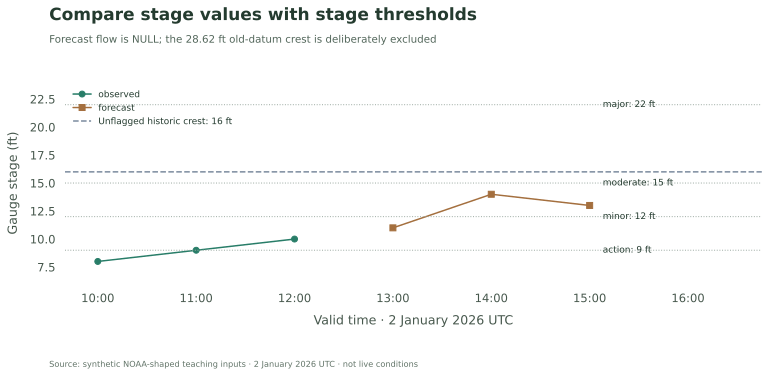

In [14]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for product, color, marker in [("observed", "#287D68", "o"), ("forecast", "#A46F3E", "s")]:
    rows = stages[stages["product"] == product]
    ax.plot(rows.valid_at, rows.primary_value, marker=marker, color=color, label=product)
for r in thresholds.itertuples():
    ax.axhline(r.stage, color="#9CAAA2", linestyle=":", linewidth=1)
    ax.text(
        pd.Timestamp("2026-01-02T15:08Z"), r.stage, f"{r.category}: {r.stage:g} ft", va="center", fontsize=9
    )
ax.axhline(16, color="#77879B", linestyle="--", label="Unflagged historic crest: 16 ft")
ax.set(
    xlabel="Valid time · 2 January 2026 UTC",
    ylabel="Gauge stage (ft)",
    ylim=(6, 24),
    xlim=(pd.Timestamp("2026-01-02T09:40Z"), pd.Timestamp("2026-01-02T16:45Z")),
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz="UTC"))
ax.legend(loc="upper left", fontsize=9)
finish(
    fig,
    "Compare stage values with stage thresholds",
    "Forecast flow is NULL; the 28.62 ft old-datum crest is deliberately excluded",
    PROVENANCE,
    name="gauge-stage-context",
)

### Preserve low-water text and missing history

Low-water information is a separate boundary. A negative stage is possible relative to
a gauge datum; it is not a negative water depth. The numeric low-water threshold is
usable as a threshold, while impact descriptions retain source text such as “Unknown”.
Do not extract a made-up numeric threshold from that text. A historic record whose
sentinel date becomes NULL stays undated and cannot enter a dated trend.

In [15]:
%%sql
CREATE TABLE low_threshold AS SELECT * FROM nws.main.low_water_threshold('RMDV2');
CREATE TABLE low_impacts AS SELECT * FROM nws.main.low_water_impacts('RMDV2');
CREATE TABLE low_history AS SELECT * FROM nws.main.historic_low_water('RMDV2');
SELECT threshold,unit FROM low_threshold;
SELECT value_text,statement FROM low_impacts;
SELECT occurred_at,stage,stage_unit,statement,occurred_at IS NOT NULL AS dated_record FROM low_history;
SELECT max(primary_value) FILTER(WHERE product='forecast') AS forecast_max_ft,
 (SELECT stage FROM thresholds WHERE category='minor') AS minor_threshold_ft,
 (SELECT threshold FROM low_threshold) AS low_threshold_ft FROM stage_series;

,forecast_max_ft,minor_threshold_ft,low_threshold_ft
0,14.0,12.0,-1.0


In [16]:
prose(
    "The synthetic forecast maximum is **14 ft**, above the **12 ft minor-stage threshold** and below **15 ft moderate**. This comparison is about the supplied stage values, not an issued warning. The low-water threshold is **−1 ft**; two impact texts remain descriptive, and only **one of two** historical low-water rows has a usable date. No current water-availability claim follows."
)

The synthetic forecast maximum is **14 ft**, above the **12 ft minor-stage threshold** and below **15 ft moderate**. This comparison is about the supplied stage values, not an issued warning. The low-water threshold is **−1 ft**; two impact texts remain descriptive, and only **one of two** historical low-water rows has a usable date. No current water-availability claim follows.

In [17]:
%%sql checks <<
SELECT 'nearby interfaces agree' AS check_name,NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM nearby EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM nearby_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM nearby_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM nearby)) AS passed
UNION ALL SELECT 'network interfaces agree',NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM network EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM network_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM network_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM network))
UNION ALL SELECT 'distance cutoff',count(*)>0 AND bool_and(distance_km<={{RADIUS_KM}}) FROM nearby
UNION ALL SELECT 'two directions three identifiers',count(*)=3 AND count(DISTINCT direction)=2 FROM network
UNION ALL SELECT 'no shared network candidates',count(*)=0 FROM nearby JOIN network USING(gauge_id)
UNION ALL SELECT 'selected identity retained',count(*)=1 AND min(reach_id)='8574021' FROM gauge_detail
UNION ALL SELECT 'six stage times',count(*)=6 AND count(DISTINCT(product,valid_at))=6 FROM stage_series
UNION ALL SELECT 'native units remain distinct',bool_and(primary_unit='ft' AND secondary_unit='kcfs') FROM stage_series
UNION ALL SELECT 'forecast flow is missing',count(*)=3 AND count(secondary_value)=0 FROM stage_series WHERE product='forecast'
UNION ALL SELECT 'four stage thresholds',count(*)=4 AND bool_and(stage_unit='ft' AND flow_unit='cfs') FROM thresholds
UNION ALL SELECT 'two impact statements',count(*)=2 AND count(statement)=2 FROM impacts
UNION ALL SELECT 'one old-datum crest excluded',count(*)=2 AND count(*) FILTER(WHERE old_datum)=1 FROM crests
UNION ALL SELECT 'negative low stage is explicit',count(*)=1 AND min(threshold)=-1 AND min(unit)='ft' FROM low_threshold
UNION ALL SELECT 'raw impact text retained',count(*)=2 AND count(*) FILTER(WHERE value_text='Unknown')=1 FROM low_impacts
UNION ALL SELECT 'undated history retained',count(*)=2 AND count(occurred_at)=1 FROM low_history;

In [18]:
assert len(checks) == 15 and checks.passed.all()
requests = source.audit()
display(checks)
Path("artifacts/gauge-audit.json").write_text(
    json.dumps(
        {
            "parameter": RADIUS_KM,
            "nearby": nearby.to_dict("records"),
            "network": network.to_dict("records"),
            "stages": stages.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)
prose(
    f"All **{len(checks)} controls** pass across **{len(requests)} bounded local requests**. The positional and named-option interfaces agree; they read the same synthetic sources."
)

,check_name,passed
0,nearby interfaces agree,True
1,network interfaces agree,True
2,distance cutoff,True
3,two directions three identifiers,True
4,no shared network candidates,True
5,selected identity retained,True
6,six stage times,True
7,native units remain distinct,True
8,forecast flow is missing,True
9,four stage thresholds,True


All **15 controls** pass across **5 bounded local requests**. The positional and named-option interfaces agree; they read the same synthetic sources.

### Experiment: widen proximity without changing the river

Change **RADIUS_KM from 25 to 50**. The geographic shortlist grows from one to two
gauges, while the reported network, selected-gauge records and stage figure stay
identical. The added candidate has no current observation timestamp. A larger radius
changes a search result, not the state of a river. Restore 25 afterward.

In [19]:
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
source.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nws](https://github.com/Query-farm/vgi-nws)